# Modelagem do problema: demanda e tempos da central de atendimento

Queremos medir **quando os chamados chegam e quanto tempo cada etapa leva**, preservando a possibilidade de auditar erros da origem. A fonte principal é `Chamados_Hora.CSV`; `chamados.csv` fornece o contexto do chamado e permite conferir o relacionamento.

## Grão e relacionamentos

| Tabela | Grão / chave | Responsabilidade |
|---|---|---|
| Bronze chamados_hora | uma linha entregue no arquivo; repetição permitida | preservar horários textuais e metadados |
| Bronze chamados | uma linha entregue no arquivo; repetição permitida | preservar contexto original |
| Silver chamados | uma linha por id_chamado não conflitante | contexto deduplicado com regra auditável |
| Silver chamados_temporais | uma linha por id_chamado | horários tipados, durações em segundos, flags e validade por métrica |
| Silver ocorrencias_qualidade | um chamado com pelo menos uma flag | investigar problema sem apagar a linha da Silver |
| Gold fato_chamados_temporais | uma linha por id_chamado | fato detalhado com dimensões temporais e medidas válidas |
| Gold dim_data | uma linha por data | calendário contínuo, ano, mês, dia da semana |
| Gold dim_hora | uma linha por hora do dia (0–23) | dimensão reutilizada pelos três papéis de horário |
| Gold chamados_por_hora | uma linha por data + hora de abertura | demanda e distribuição dos tempos por coorte de abertura |
| Gold chamados_por_dia | uma linha por data de abertura | demanda diária, cobertura e tempos |

`ID_Chamado` é a **chave primária esperada** da tabela temporal e a ligação com o chamado de origem. O relacionamento lógico é 1:0..1 depois de validar unicidade. O nome CHAMADOS_HORA não significa uma linha por hora: o grão original é um chamado. Um grão fino também não implica Big Data; os arquivos atuais têm aproximadamente 12 e 15 MB.

No fato detalhado, `data_abertura`, `data_inicio` e `data_fim` referenciam a mesma `dim_data` em papéis distintos; os três campos de hora referenciam `dim_hora`. Os IDs de cliente são mantidos como texto; não há dimensão cadastral de cliente fornecida. Não fabricamos atributos ou histórico SCD2.

## Fluxo escolhido: batch com ELT

`CSV → Bronze persistida → Silver temporal + auditoria do vínculo → Gold → consultas SQL / gráficos`

Para esta entrega, **batch** é adequado: a entrada é uma fotografia em arquivos e não foi exigida resposta a eventos em segundos. A frequência futura pode ser diária ou por chegada de arquivo, conforme o contrato da operação. **ELT** descreve carregar os dados brutos no ambiente analítico antes de aplicar as regras. **ETL** seria transformar antes de carregar no destino analítico; pode ser adequado se esse destino só aceitar dados já tratados. Batch/streaming e ETL/ELT são decisões diferentes.

Aqui o fluxo está materializado localmente em **Parquet**, sem alegar transações Delta/ACID. Cada lote Bronze usa SHA-256 do arquivo como identidade e mantém uma cópia do original. Reexecutar o mesmo lote reutiliza a Bronze; Silver/Gold são reconstruídas por lote, sem append duplicado. Um novo arquivo com conteúdo diferente cria outro lote; não unimos snapshots automaticamente, pois não existe versão de alteração para resolver sobreposições.

A escolha das camadas segue a organização geral [Bronze / Silver / Gold do Databricks](https://docs.databricks.com/aws/en/lakehouse/medallion). A distinção de ordem entre [ETL e ELT está descrita pela AWS](https://aws.amazon.com/compare/the-difference-between-etl-and-elt/). O desenho concreto e a escolha por batch são decisões deste caso.

## Regras temporais e de qualidade

- Datas de origem sem fuso: TIMESTAMP_NTZ; nenhuma conversão presumida para UTC.
- Espera = início − abertura; atendimento = fim − início; total = fim − abertura.
- Duração ausente/inválida permanece NULL. Zero é observação válida quando a sequência é possível.
- Abertura futura e sequência invertida recebem flags. Não corrigimos o ano sem evidência.
- Validade é específica por indicador: ausência de início invalida espera/atendimento, mas pode permitir tempo total.
- Duplicata exata é removida na Silver. Versões diferentes do mesmo ID são segregadas, sem seleção arbitrária.
- Divergência de cliente entre as fontes é exposta. O cliente original da tabela temporal não é sobrescrito.
- A hora do agregado representa **abertura**: seus tempos são dos chamados que chegaram naquela hora, mesmo que terminem depois. Não representa ocupação, fila em andamento ou quantidade encerrada naquela hora.

## Consultas analíticas previstas

1. Quais datas e horas concentram mais aberturas?
2. Qual é a espera média e o P95 em cada coorte horária, e qual a cobertura da métrica?
3. Como evoluem volume diário e média móvel de sete dias?
4. Como a demanda varia por dia da semana e hora, corrigindo a exposição em dias?
5. Qual a distribuição de espera, atendimento e tempo total, com denominador próprio?
6. Quanto os indicadores mudam mês a mês? Quais meses podem estar incompletos?
7. Quantos chamados têm problemas temporais, conflito de chave ou divergência entre fontes?
8. Qual proporção das esperas válidas fica abaixo de limites de cenário? Sem contrato, não chamar isso de SLA cumprido.

As consultas SQL executáveis aparecem depois da persistência da Gold e também em `consultas_analiticas.sql`. Percentis devem ser recalculados no fato; **não se faz média de P95**. Médias agregadas são recompostas por soma de segundos / número de observações válidas.

# Análise temporal de chamados com PySpark
## Do diagnóstico da fonte às conclusões de negócio

**Fonte:** `Chamados_Hora.CSV` fornecido pelo usuário. **Referência da análise:** 18/10/2026.

Este notebook aplica os conceitos das aulas Rocket Lab: grão, Bronze → Silver → Gold, qualidade antes das métricas, calendário contínuo, funções de janela, rastreabilidade e validação das agregações. Os códigos estão separados em blocos pequenos e os resultados são interpretados ao longo da análise.

**Perguntas:** quantos chamados existem, quais registros são confiáveis, quanto se espera, quanto dura o atendimento, como a demanda varia e quais melhorias podem ser investigadas?

**Limites:** a fonte temporal não declara fuso. O arquivo complementar fornece canal, motivo e ID de atendente, sujeitos à auditoria do vínculo; não fornece escala, custo, satisfação ou meta contratual de SLA. Os IDs são identificadores, sem presumir que `ID_Cliente` seja CPF. Não há histórico de versões para implementar SCD2 real.

Execute as células em ordem. A primeira execução necessita de Java 17 e das dependências em `requirements.txt`. No Databricks, adapte o caminho e aproveite a sessão `spark` existente. Não execute a instalação de pacotes automaticamente em cada análise.

## 1. Contrato da análise e parâmetros

**Grão esperado:** uma linha por `ID_Chamado`. Preserve IDs como strings, incluindo possíveis zeros à esquerda. As datas têm dia/mês/ano e o literal `às`.

A referência é fixa para que reexecutar o notebook não mude silenciosamente o diagnóstico de datas futuras. O intervalo opcional filtra **aberturas**, com início inclusivo e fim exclusivo. `None` usa toda a fonte, sem impor o período de um exercício anterior.

Os horários são tratados como **TIMESTAMP_NTZ**, campos de relógio sem fuso. As durações são diferenças nominais nesses horários. Para medir tempo físico atravessando fusos ou horário de verão, obtenha primeiro o contrato de fuso da origem; UTC da sessão não confirma que a fonte seja UTC.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from pyspark.sql import SparkSession, functions as F, types as T, Window

# AJUSTE SOMENTE ESTAS ENTRADAS. No Databricks use /Volumes/catalogo/schema/volume/...
path = "/home/perri/Downloads/Chamados_Hora.CSV"
path_chamados = "/home/perri/Downloads/chamados.csv"
path_saida = "."   # Databricks: /Volumes/catalogo/schema/volume/entregas/chamados
ARQUIVO = Path(path)
SAIDA = Path(path_saida).resolve()
DATA_REFERENCIA = "2026-10-18"
INICIO_ABERTURA = None             # exemplo: "2025-01-01"
FIM_ABERTURA_EXCLUSIVO = None       # exemplo: "2026-08-01"
SLA_CONTRATUAL_MIN = None           # só preencher após confirmação do negócio
LIMITES_CENARIO_MIN = [1, 5, 10, 15, 30]
for pasta in ["resultados", "graficos"]:
    (SAIDA / pasta).mkdir(parents=True, exist_ok=True)
assert ARQUIVO.is_file(), f"Arquivo não encontrado: {ARQUIVO}. Ajuste path."
ARQUIVO_CHAMADOS = Path(path_chamados)
assert ARQUIVO_CHAMADOS.is_file(), "Ajuste path_chamados."

In [2]:
spark_existente = SparkSession.getActiveSession()
spark = spark_existente or (SparkSession.builder.master("local[2]")
    .appName("analise-chamados-hora")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.ui.enabled", "false").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
spark.conf.set("spark.sql.session.timeZone", "UTC")
spark.conf.set("spark.sql.timestampType", "TIMESTAMP_NTZ")
spark.conf.set("spark.sql.ansi.enabled", "true")
spark.conf.set("spark.sql.legacy.timeParserPolicy", "CORRECTED")
plt.rcParams.update({"figure.figsize": (11, 4.3), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
metadados = {"arquivo": ARQUIVO.name, "bytes": ARQUIVO.stat().st_size,
    "sha256": hashlib.sha256(ARQUIVO.read_bytes()).hexdigest(),
    "referencia": DATA_REFERENCIA, "spark": spark.version,
    "python": platform.python_version(), "pandas": pd.__version__,
    "fuso_origem": "não informado", "duracao": "horário local nominal",
    "inicio_abertura": INICIO_ABERTURA, "fim_exclusivo": FIM_ABERTURA_EXCLUSIVO}
display(pd.DataFrame([metadados]).drop(columns=["sha256"]).T.rename(columns={0: "valor"}))

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/18 20:48:24 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


,valor
arquivo,Chamados_Hora.CSV
bytes,11547467
referencia,2026-10-18
spark,3.5.6
python,3.12.3
pandas,2.2.3
fuso_origem,não informado
duracao,horário local nominal
inicio_abertura,None
fim_exclusivo,None


## 2. Bronze: ler sem perder a evidência

**Pergunta:** o arquivo está sendo interpretado corretamente?

O CSV usa vírgula e codificação Windows-1252 compatível com os caracteres observados. Declaramos todas as colunas como texto, sem `inferSchema`. `FAILFAST` interrompe a leitura se houver quebra estrutural. Nulos de conteúdo serão classificados na Silver.

A Bronze é persistida em Parquet antes das transformações. Mantemos os campos brutos, arquivo de origem, lote SHA-256 e instante de ingestão, além de uma cópia do arquivo original. Silver e Gold também serão persistidas e relidas. A execução é local, sem Delta Lake ou Unity Catalog.

In [3]:
import shutil
from datetime import datetime, timezone
CAMADAS = SAIDA / "camadas"
lote_hora = metadados["sha256"]
lote_contexto = hashlib.sha256(ARQUIVO_CHAMADOS.read_bytes()).hexdigest()
LOTE = lote_hora[:16] + "_" + lote_contexto[:16]
RAIZ_LOTE = CAMADAS / "processado" / LOTE
RAIZ_LOTE.mkdir(parents=True, exist_ok=True)

def carregar_bronze(arquivo, encoding, colunas):
    digest = hashlib.sha256(arquivo.read_bytes()).hexdigest()
    destino = CAMADAS / "bronze" / arquivo.stem.lower() / digest
    destino.mkdir(parents=True, exist_ok=True)
    original = destino / arquivo.name
    if not original.exists():
        shutil.copy2(arquivo, original)
    assert hashlib.sha256(original.read_bytes()).hexdigest() == digest
    tabela = destino / "dados"
    if not tabela.exists():
        estrutura = T.StructType([T.StructField(c, T.StringType(), True) for c in colunas])
        raw = (spark.read.option("header", "true").option("sep", ",")
            .option("encoding", encoding).option("mode", "FAILFAST")
            .schema(estrutura).csv(str(original)))
        raw = (raw.withColumn("_arquivo_origem", F.lit(arquivo.name))
            .withColumn("_lote_sha256", F.lit(digest))
            .withColumn("_ingerido_em_utc", F.lit(datetime.now(timezone.utc).isoformat())))
        raw.write.mode("errorifexists").parquet(str(tabela))
    return spark.read.parquet(str(tabela))

colunas_originais = ["ID_Chamado", "ID_Cliente", "Hora_Abertura_Chamado",
    "Hora_Inicio_Atendimento", "Hora_Finalizacao_Atendimento"]
colunas_contexto = ["id_chamado", "id_cliente", "motivo", "canal", "resolvido",
    "hora_abertura_chamado", "hora_inicio_atendimento", "hora_finalizacao_atendimento",
    "tempo_espera", "tempo_atendimento", "id_atendente"]
# Contrato de cabeçalho: evita associar silenciosamente a coluna errada ao schema.
import csv
for arquivo, encoding, esperado in [(ARQUIVO, "cp1252", colunas_originais),
                                   (ARQUIVO_CHAMADOS, "utf-8-sig", colunas_contexto)]:
    with arquivo.open(encoding=encoding, newline="") as f:
        assert next(csv.reader(f)) == esperado, f"Cabeçalho diferente do contrato: {arquivo.name}"
bronze = carregar_bronze(ARQUIVO, "windows-1252", colunas_originais).cache()
bronze_contexto = carregar_bronze(ARQUIVO_CHAMADOS, "UTF-8", colunas_contexto).cache()
n_bruto = bronze.count()
n_exatas = n_bruto - bronze.dropDuplicates(colunas_originais).count()
base = bronze.dropDuplicates(colunas_originais)
conflitos = base.groupBy("ID_Chamado").count().filter("count > 1").count()
assert conflitos == 0, "Há versões temporais conflitantes; exige regra de versão antes de publicar."
n_base = base.count()
display(pd.DataFrame({"verificação": ["Linhas temporais brutas", "Duplicatas exatas", "Chamados temporais", "IDs conflitantes", "Linhas de contexto brutas"],
                      "quantidade": [n_bruto, n_exatas, n_base, conflitos, bronze_contexto.count()]}))
display(bronze.select(*colunas_originais[2:]).limit(5).toPandas())

,verificação,quantidade
0,Linhas temporais brutas,131838
1,Duplicatas exatas,0
2,Chamados temporais,131838
3,IDs conflitantes,0
4,Linhas de contexto brutas,134474


,Hora_Abertura_Chamado,Hora_Inicio_Atendimento,Hora_Finalizacao_Atendimento
0,29/06/2026 às 14:12:48,29/06/2026 às 14:21:24,29/06/2026 às 15:06:16
1,16/09/2025 às 09:03:42,16/09/2025 às 09:07:41,16/09/2025 às 10:11:50
2,03/03/2025 às 14:02:31,03/03/2025 às 14:02:31,03/03/2025 às 14:04:25
3,08/06/2026 às 15:38:20,08/06/2026 às 15:38:20,08/06/2026 às 15:40:18
4,23/09/2025 às 14:41:45,23/09/2025 às 14:41:45,23/09/2025 às 14:43:35


**Como interpretar:** a ausência de duplicatas nesta fonte não garante que cargas futuras nunca tragam reentregas. O notebook bloqueia conflitos por chave porque este CSV não informa qual seria a versão mais recente. Nenhuma linha é escolhida aleatoriamente com `dropDuplicates(["ID_Chamado"])`.

## 3. Silver: tipagem explícita e falha de parsing

A string original permanece disponível. `try_to_timestamp` gera nulo em caso de data inválida. Se o bruto estava preenchido e o convertido virou nulo, isso é **falha de parsing**; se o bruto já estava vazio, isso é **ausência na origem**. São problemas diferentes.

**Regex:** `regexp_replace` padroniza espaços ao redor de `às`, mantendo o valor original. `rlike` verifica a estrutura `dd/MM/yyyy às HH:mm:ss`. Uma expressão regular não identifica sozinha 31/02: `try_to_timestamp` verifica se a data existe. Isso separa formato inválido de falha de conversão. Não usamos regex para inventar horários ausentes ou ajustar anos.

In [4]:
FORMATO = "dd/MM/yyyy 'às' HH:mm:ss"
mapa = {"Hora_Abertura_Chamado": "abertura_ts", "Hora_Inicio_Atendimento": "inicio_ts",
        "Hora_Finalizacao_Atendimento": "fim_ts"}
silver = base.withColumnRenamed("ID_Chamado", "id_chamado").withColumnRenamed("ID_Cliente", "id_cliente")
# Regex atua no texto. A validação do calendário real cabe ao parser de timestamp.
PADRAO_DATA = r"^\d{2}/\d{2}/\d{4} às \d{2}:\d{2}:\d{2}$"
for bruto, tipado in mapa.items():
    normalizado = tipado + "_texto_normalizado"
    silver = (silver.withColumn(normalizado,
        F.regexp_replace(F.trim(F.col(bruto)), r"\s+às\s+", " às "))
        .withColumn("formato_invalido_" + tipado,
            F.col(bruto).isNotNull() & (F.trim(F.col(bruto)) != "") & ~F.col(normalizado).rlike(PADRAO_DATA))
        .withColumn(tipado, F.try_to_timestamp(F.col(normalizado), F.lit(FORMATO)))
        .withColumn("ausente_" + tipado, F.col(bruto).isNull() | (F.trim(F.col(bruto)) == ""))
        .withColumn("falha_parse_" + tipado,
                    ~F.col("ausente_" + tipado) & F.col(tipado).isNull()))
silver = (silver.withColumn("data_abertura", F.to_date("abertura_ts"))
    .withColumn("hora_abertura", F.hour("abertura_ts"))
    .withColumn("mes_abertura", F.trunc("data_abertura", "month")))
faixas = silver.agg(*[expr for c in mapa.values() for expr in
    (F.min(c).alias(c + "_min"), F.max(c).alias(c + "_max"))]).first().asDict()
display(pd.DataFrame([faixas]).T.rename(columns={0: "valor"}))

,valor
abertura_ts_min,2025-01-01 06:31:22
abertura_ts_max,2027-12-23 06:46:00
inicio_ts_min,2025-01-01 06:31:22
inicio_ts_max,2026-07-31 17:05:01
fim_ts_min,2025-01-01 06:36:30
fim_ts_max,2026-07-31 17:44:22


## 4. Qualidade temporal antes das métricas

**Pergunta:** os horários representam uma sequência possível?

Registramos os problemas em flags independentes. Um chamado pode ter mais de um problema; somar as contagens de flags não equivale a contar chamados com problema.

Abertura em 2027, diante de finalização em 2026, é inconsistente. A evidência não permite concluir qual deveria ser o ano correto: não subtraímos um ano automaticamente. Ausência de início não é substituída pelo horário da abertura.

In [5]:
def flag(condicao):
    return F.coalesce(condicao, F.lit(False))

silver = (silver
    .withColumn("chave_ausente", flag(F.col("id_chamado").isNull() | (F.trim("id_chamado") == "")))
    .withColumn("cliente_ausente", flag(F.col("id_cliente").isNull() | (F.trim("id_cliente") == "")))
    .withColumn("abertura_futura", flag(F.col("data_abertura") > F.lit(DATA_REFERENCIA).cast("date")))
    .withColumn("inicio_antes_abertura", flag(F.col("inicio_ts") < F.col("abertura_ts")))
    .withColumn("fim_antes_abertura", flag(F.col("fim_ts") < F.col("abertura_ts")))
    .withColumn("fim_antes_inicio", flag(F.col("fim_ts") < F.col("inicio_ts"))))
flags_temporais = ["ausente_" + c for c in mapa.values()] + ["falha_parse_" + c for c in mapa.values()] + ["formato_invalido_" + c for c in mapa.values()] + [
    "chave_ausente", "cliente_ausente", "abertura_futura", "inicio_antes_abertura", "fim_antes_abertura", "fim_antes_inicio"]
cond_problema = F.lit(False)
for nome in flags_temporais:
    cond_problema = cond_problema | F.col(nome)
silver = silver.withColumn("tem_problema", cond_problema).cache()
contagens = silver.agg(*[F.sum(F.col(c).cast("long")).alias(c) for c in flags_temporais]).first().asDict()
qualidade = pd.DataFrame([{"regra": k, "n": int(v or 0), "percentual_base": 100 * (v or 0) / n_base}
                         for k, v in contagens.items()]).sort_values("n", ascending=False)
display(qualidade)
n_problema = silver.filter("tem_problema").count()
print(f"Chamados com pelo menos um problema: {n_problema:,} de {n_base:,}.")

,regra,n,percentual_base
1,ausente_inicio_ts,3414,2.589542
13,fim_antes_abertura,199,0.150943
11,abertura_futura,198,0.150184
12,inicio_antes_abertura,192,0.145633
14,fim_antes_inicio,1,0.000759
0,ausente_abertura_ts,0,0.000000
2,ausente_fim_ts,0,0.000000
6,formato_invalido_abertura_ts,0,0.000000
5,falha_parse_fim_ts,0,0.000000
4,falha_parse_inicio_ts,0,0.000000


Chamados com pelo menos um problema: 3,607 de 131,838.


,problemas,count
0,sem flag de qualidade,128231
1,ausente_inicio_ts,3408
2,abertura_futura + inicio_antes_abertura + fim_...,192
3,ausente_inicio_ts + abertura_futura + fim_ante...,6
4,fim_antes_abertura + fim_antes_inicio,1


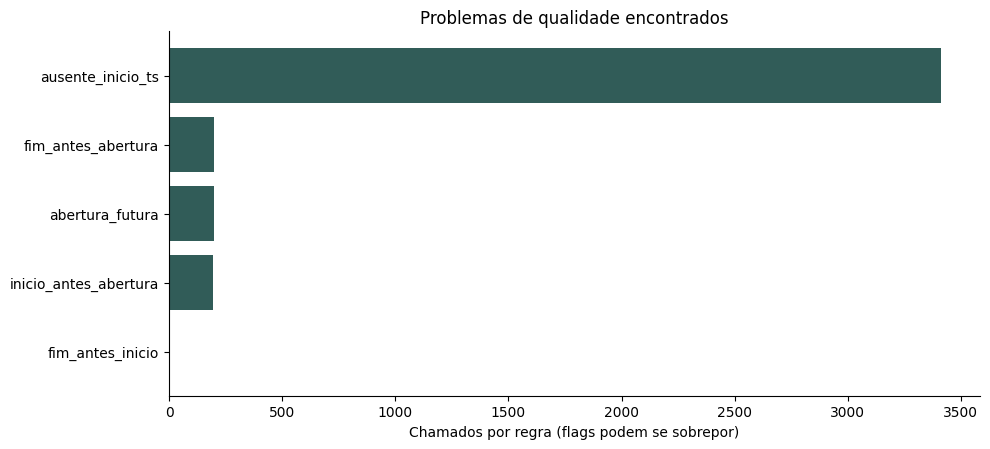

In [6]:
# Distribuição das combinações; não publica IDs individuais.
combinacoes = (silver.select(F.concat_ws(" + ", *[
    F.when(F.col(c), F.lit(c)) for c in flags_temporais]).alias("problemas"))
    .groupBy("problemas").count().orderBy(F.desc("count")).toPandas())
combinacoes["problemas"] = combinacoes["problemas"].replace("", "sem flag de qualidade")
display(combinacoes)
fig, ax = plt.subplots(figsize=(10, 4.6))
q = qualidade.query("n > 0").sort_values("n")
ax.barh(q.regra, q.n, color="#315c58")
ax.set(xlabel="Chamados por regra (flags podem se sobrepor)", title="Problemas de qualidade encontrados")
fig.tight_layout(); fig.savefig(SAIDA / "graficos/01_qualidade.png", dpi=170); plt.show()

## 5. Critério de validade por indicador

| Indicador | Cálculo nominal | Critério publicado |
|---|---|---|
| Espera | início − abertura | abertura válida no corte; início presente, não futuro e ≥ abertura |
| Atendimento | fim − início | sequência completa abertura ≤ início ≤ fim; fim não futuro |
| Tempo total | fim − abertura | abertura e fim válidos; fim ≥ abertura; pode faltar início |

O tempo de atendimento pode ser aritmeticamente positivo mesmo quando a abertura está depois do início. Essa linha não descreve um ciclo confiável de atendimento; por isso, a métrica de negócio de atendimento exige a cadeia completa. O diagnóstico também mostra quantos pares seriam positivos sem essa regra.

Nulos continuam nulos. Espera igual a zero pode ser válida e não prova atendimento automatizado. Não removemos valores altos só por parecerem outliers.

In [7]:
ref = F.lit(DATA_REFERENCIA).cast("date")
chave_ok = ~F.col("chave_ausente")
ab_ok = chave_ok & F.col("abertura_ts").isNotNull() & (F.col("data_abertura") <= ref)
esp_ok = ab_ok & F.col("inicio_ts").isNotNull() & (F.col("inicio_ts") >= F.col("abertura_ts")) & (F.to_date("inicio_ts") <= ref)
at_ok = esp_ok & F.col("fim_ts").isNotNull() & (F.col("fim_ts") >= F.col("inicio_ts")) & (F.to_date("fim_ts") <= ref)
total_ok = ab_ok & F.col("fim_ts").isNotNull() & (F.col("fim_ts") >= F.col("abertura_ts")) & (F.to_date("fim_ts") <= ref)
silver = (silver.withColumn("abertura_valida", flag(ab_ok))
    .withColumn("espera_valida", flag(esp_ok)).withColumn("atendimento_valido", flag(at_ok))
    .withColumn("total_valido", flag(total_ok)))
for metrica, inicio, fim, valido in [
    ("espera", "abertura_ts", "inicio_ts", "espera_valida"),
    ("atendimento", "inicio_ts", "fim_ts", "atendimento_valido"),
    ("total", "abertura_ts", "fim_ts", "total_valido")]:
    silver = (silver.withColumn(metrica + "_bruto_s", F.expr(f"timestampdiff(SECOND, {inicio}, {fim})"))
        .withColumn(metrica + "_s", F.when(F.col(valido), F.col(metrica + "_bruto_s"))))
# O filtro de escopo vem dos parâmetros; não de uma data inferida no relatório anterior.
analise = silver
if INICIO_ABERTURA:
    analise = analise.filter(F.col("data_abertura") >= F.lit(INICIO_ABERTURA).cast("date"))
if FIM_ABERTURA_EXCLUSIVO:
    analise = analise.filter(F.col("data_abertura") < F.lit(FIM_ABERTURA_EXCLUSIVO).cast("date"))
analise = analise.cache()
volume = analise.filter("abertura_valida").cache()
n_volume = volume.count()
assert n_volume > 0, "O escopo selecionado não tem aberturas válidas."
print("Atendimento: pares não negativos:", analise.filter("atendimento_bruto_s >= 0").count(),
      "| ciclos completos válidos:", analise.filter("atendimento_valido").count())
print("Aberturas válidas para analisar demanda:", f"{n_volume:,}")

Atendimento: pares não negativos: 128423 | ciclos completos válidos: 128231
Aberturas válidas para analisar demanda: 131,640


## Silver: relacionamento seguro e persistência

O join usa somente `id_chamado`, após conferir a cardinalidade. Primeiro removemos duplicatas **exatas do contexto**, considerando todos os atributos originais; depois identificamos versões diferentes por chave. IDs conflitantes ficam em tabela própria e não participam do enriquecimento. A Silver temporal mantém todos os chamados e indica vínculo ausente ou conflitante.

Nenhum tempo pré-calculado em chamados.csv substitui o cálculo por timestamps do arquivo temporal. As ocorrências de qualidade são uma visão para investigação: a validade de cada medida continua sendo definida individualmente. Não excluímos um chamado inteiro de todas as métricas só porque falta um horário.

In [8]:
ctx_distinto = bronze_contexto.dropDuplicates(colunas_contexto)
ctx_contagens = ctx_distinto.groupBy("id_chamado").count()
ctx_conflitos = ctx_contagens.filter("count > 1").select("id_chamado")
ctx_sem_chave = ctx_distinto.filter(F.col("id_chamado").isNull() | (F.trim("id_chamado") == ""))
ctx_conflitantes = ctx_distinto.join(ctx_conflitos, "id_chamado", "inner")
ctx_silver = (ctx_distinto.join(ctx_conflitos, "id_chamado", "left_anti")
    .filter(F.col("id_chamado").isNotNull() & (F.trim("id_chamado") != "")))
assert ctx_silver.count() == ctx_silver.select("id_chamado").distinct().count()
# A contagem prevista usa as linhas brutas, sem realizar um join que multiplicaria a análise.
mult = bronze_contexto.groupBy("id_chamado").count().withColumnRenamed("count", "n_contexto")
fanout = (silver.select("id_chamado").join(mult, "id_chamado", "left")
    .agg(F.sum(F.coalesce("n_contexto", F.lit(1))).alias("n")).first().n)
ctx_enriquecimento = ctx_silver.select("id_chamado", F.col("id_cliente").alias("id_cliente_contexto"),
    "motivo", "canal", "resolvido", "id_atendente", F.lit(True).alias("contexto_encontrado"))
conflito_flag = ctx_conflitos.withColumn("contexto_conflitante", F.lit(True))
silver = (silver.join(ctx_enriquecimento, "id_chamado", "left")
    .join(conflito_flag, "id_chamado", "left")
    .withColumn("contexto_encontrado", F.coalesce("contexto_encontrado", F.lit(False)))
    .withColumn("contexto_conflitante", F.coalesce("contexto_conflitante", F.lit(False)))
    .withColumn("cliente_divergente", F.col("contexto_encontrado") & ~F.col("id_cliente").eqNullSafe(F.col("id_cliente_contexto"))))
assert silver.count() == n_base
resumo_vinculo = {"linhas_contexto_brutas": bronze_contexto.count(),
    "duplicatas_exatas_contexto": bronze_contexto.count() - ctx_distinto.count(),
    "ids_conflitantes_contexto": ctx_conflitos.count(),
    "linhas_contexto_sem_chave": ctx_sem_chave.count(),
    "linhas_previstas_join_bruto": fanout,
    "linhas_join_seguro": silver.count(),
    "clientes_divergentes": silver.filter("cliente_divergente").count(),
    "sem_contexto_utilizavel": silver.filter("NOT contexto_encontrado").count(),
    "contexto_sem_temporal": ctx_distinto.select("id_chamado").distinct().join(silver.select("id_chamado"), "id_chamado", "left_anti").count()}
display(pd.DataFrame([resumo_vinculo]).T.rename(columns={0: "quantidade"}))
(SAIDA / "resultados/auditoria_vinculo.json").write_text(json.dumps(resumo_vinculo, indent=2), encoding="utf-8")

def persistir(df, camada, nome):
    caminho = RAIZ_LOTE / camada / nome
    df.write.mode("overwrite").parquet(str(caminho))
    return spark.read.parquet(str(caminho))

ctx_silver = persistir(ctx_silver, "silver", "chamados")
persistir(ctx_conflitantes, "silver", "chamados_conflitantes")
persistir(ctx_sem_chave, "silver", "chamados_sem_chave")
silver = persistir(silver, "silver", "chamados_temporais")
ocorrencias = silver.filter("tem_problema OR cliente_divergente OR NOT contexto_encontrado")
persistir(ocorrencias, "silver", "ocorrencias_qualidade")
# Recria o escopo a partir da Silver relida do disco.
analise = silver
if INICIO_ABERTURA:
    analise = analise.filter(F.col("data_abertura") >= F.lit(INICIO_ABERTURA).cast("date"))
if FIM_ABERTURA_EXCLUSIVO:
    analise = analise.filter(F.col("data_abertura") < F.lit(FIM_ABERTURA_EXCLUSIVO).cast("date"))
analise = analise.cache()
volume = analise.filter("abertura_valida").cache()
assert volume.count() == n_volume
print("Silver gravada e relida:", RAIZ_LOTE / "silver")

,quantidade
linhas_contexto_brutas,134474
duplicatas_exatas_contexto,2636
ids_conflitantes_contexto,0
linhas_contexto_sem_chave,0
linhas_previstas_join_bruto,134474
linhas_join_seguro,131838
clientes_divergentes,1330
sem_contexto_utilizavel,0
contexto_sem_temporal,0


Silver gravada e relida: /home/perri/Documentos/ChatGPT/visagio/entregas/analise_chamados_jupyter/camadas/processado/d971b56d13d145cf_feb33076a4396b61/silver


## 6. Gold: indicadores gerais com denominadores explícitos

**Pergunta:** quanto tempo o cliente espera e quanto dura cada etapa?

A média é sensível à cauda. A mediana descreve o centro; P90, P95 e P99 ajudam a observar os casos mais demorados. Aqui usamos percentis exatos do Spark para este arquivo; na escala de produção, uma aproximação pode ser escolhida e documentada.

A tabela informa o número de observações de cada métrica. Comparar médias calculadas em bases diferentes sem informar os denominadores pode esconder perda de qualidade.

In [9]:
linhas_kpi = []
for metrica in ["espera", "atendimento", "total"]:
    c = metrica + "_s"
    r = analise.agg(F.count(c).alias("n"), F.avg(c).alias("media_s"),
        F.min(c).alias("min_s"), F.max(c).alias("max_s"),
        F.sum(F.when(F.col(c) == 0, 1).otherwise(0)).alias("zeros"),
        F.expr(f"percentile({c}, array(0.5, 0.9, 0.95, 0.99))").alias("p")).first()
    assert r.n > 0, f"Sem observações válidas para {metrica}"
    linhas_kpi.append({"metrica": metrica, "n_validos": r.n,
        "cobertura_pct_base_escopo": 100 * r.n / analise.count(),
        "media_min": r.media_s / 60, "p50_min": r.p[0] / 60,
        "p90_min": r.p[1] / 60, "p95_min": r.p[2] / 60,
        "p99_min": r.p[3] / 60, "max_min": r.max_s / 60,
        "zeros_n": r.zeros, "zeros_pct_validos": 100 * r.zeros / r.n})
kpis = pd.DataFrame(linhas_kpi)
display(kpis.round(3))

,metrica,n_validos,cobertura_pct_base_escopo,media_min,p50_min,p90_min,p95_min,p99_min,max_min,zeros_n,zeros_pct_validos
0,espera,128232,97.265,3.600,0.000,11.382,16.367,30.100,103.867,74939,58.44
1,atendimento,128231,97.264,11.030,4.267,29.167,41.650,73.985,150.000,0,0.00
2,total,131639,99.849,14.651,4.683,39.353,54.633,90.150,197.800,0,0.00


In [10]:
# Identidade temporal: comparar no MESMO conjunto de chamados completos.
completos = analise.filter("atendimento_valido AND espera_valida AND total_valido")
erro_identidade = completos.filter(F.col("total_s") != F.col("espera_s") + F.col("atendimento_s")).count()
assert erro_identidade == 0
comparacao = completos.agg(F.count("id_chamado").alias("n_completos"),
    *[F.avg(m + "_s").alias(m + "_media_s") for m in ["espera", "atendimento", "total"]]).toPandas()
display(comparacao)
display(Markdown("**Interpretação:** no mesmo conjunto, tempo total = espera + atendimento. "
    "As médias gerais da tabela anterior usam denominadores próprios e não precisam obedecer à soma entre si."))

,n_completos,espera_media_s,atendimento_media_s,total_media_s
0,128231,216.022959,661.782377,877.805336


**Interpretação:** no mesmo conjunto, tempo total = espera + atendimento. As médias gerais da tabela anterior usam denominadores próprios e não precisam obedecer à soma entre si.

## 7. Espera zero e distribuição dos tempos

**Pergunta:** a média representa todos os chamados?

Mostramos separadamente a fração com espera zero e a distribuição entre quem possui espera positiva. A série abaixo é limitada aos tempos observáveis: não interpreta ausência de horário como zero nem presume um canal de atendimento.

O histograma usa **todo** o conjunto válido agregado em faixas de um minuto; a figura mostra até P99, com a quantidade fora do eixo informada. Os registros de cauda continuam nas métricas e na tabela de faixas exportada.

,n,media_s,p50_s
0,53293,519.790723,386.0


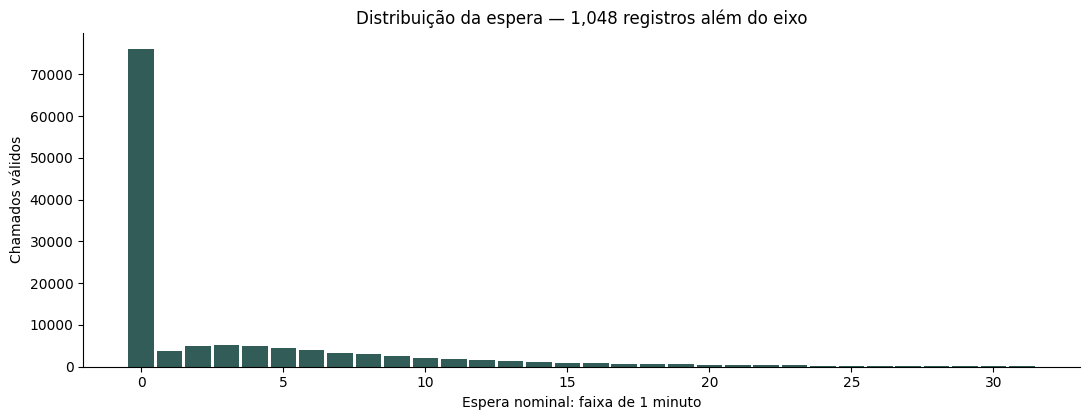

In [11]:
espera_pos = analise.filter("espera_s > 0").agg(F.count("espera_s").alias("n"),
    F.avg("espera_s").alias("media_s"), F.expr("percentile(espera_s, 0.5)").alias("p50_s")).toPandas()
display(espera_pos)
hist = (analise.filter("espera_s IS NOT NULL").withColumn("faixa_min", F.floor(F.col("espera_s") / 60))
        .groupBy("faixa_min").count().orderBy("faixa_min").toPandas())
p99_espera = float(kpis.set_index("metrica").loc["espera", "p99_min"])
limite_grafico = int(np.ceil(p99_espera))
n_fora_eixo = analise.filter(F.col("espera_s") >= (limite_grafico + 1) * 60).count()
fig, ax = plt.subplots()
h = hist[hist.faixa_min <= limite_grafico]
ax.bar(h.faixa_min, h["count"], width=.9, color="#315c58")
ax.set(xlabel="Espera nominal: faixa de 1 minuto", ylabel="Chamados válidos",
       title=f"Distribuição da espera — {n_fora_eixo:,} registros além do eixo")
fig.tight_layout(); fig.savefig(SAIDA / "graficos/02_distribuicao_espera.png", dpi=170); plt.show()

## 8. Calendário contínuo e volume diário

**Pergunta:** existem dias sem registro? Qual é o ritmo da demanda?

O calendário vai da primeira à última **abertura válida no escopo**, sem esticar até as aberturas futuras inconsistentes. A chave `yyyyMMdd` é apenas um identificador; cálculos usam DATE.

Um zero abaixo significa **nenhuma abertura registrada neste arquivo naquele dia**. Sem controle de completude de carga, não prova ausência real de demanda. O arquivo não informa um calendário operacional ou a localidade necessária para aplicar feriados municipais. Não inventamos esse enriquecimento.

Intervalo: 2025-01-01 a 2026-07-31 | dias: 577 | dias sem registro: 0


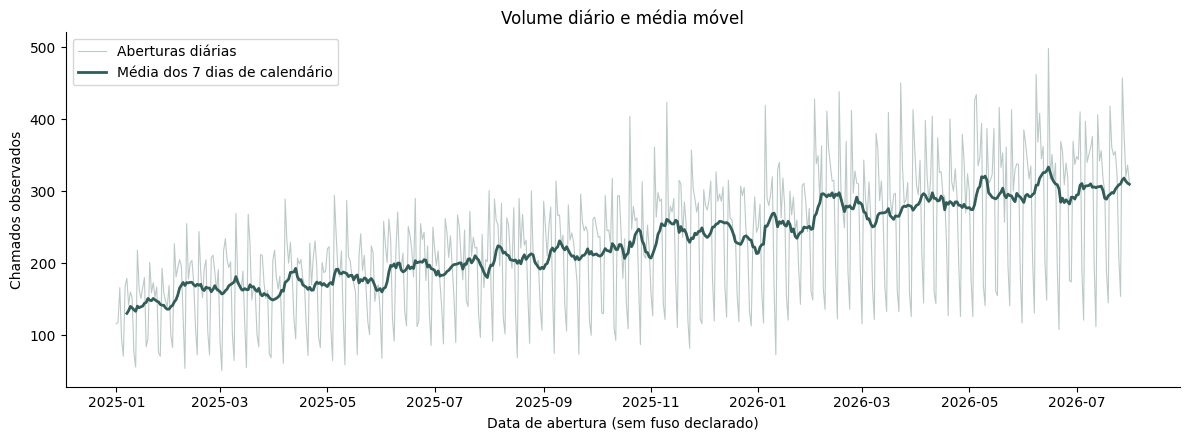

In [12]:
limites = volume.agg(F.min("data_abertura").alias("inicio"), F.max("data_abertura").alias("fim")).first()
calendario = (spark.range(1).select(F.explode(F.sequence(F.lit(limites.inicio), F.lit(limites.fim),
    F.expr("INTERVAL 1 DAY"))).alias("data"))
    .withColumn("data_sk", F.date_format("data", "yyyyMMdd").cast("int")))
por_dia = (volume.groupBy("data_abertura").agg(F.count("id_chamado").alias("chamados_observados"),
    F.count("espera_s").alias("n_espera"), F.avg("espera_s").alias("espera_media_s"),
    F.expr("percentile(espera_s, 0.95)").alias("espera_p95_s"))
    .withColumnRenamed("data_abertura", "data"))
diario = (calendario.join(por_dia, "data", "left")
    .withColumn("sem_registro_no_arquivo", F.col("chamados_observados").isNull())
    .fillna({"chamados_observados": 0, "n_espera": 0})
    .withColumn("dia_n", F.datediff("data", F.lit("1970-01-01").cast("date"))))
w7 = Window.orderBy("dia_n").rangeBetween(-6, 0)
diario = (diario.withColumn("n_dias_janela", F.count("data").over(w7))
    .withColumn("media_movel_7d", F.when(F.col("n_dias_janela") == 7,
        F.sum("chamados_observados").over(w7) / F.lit(7))))
diario_pd = diario.orderBy("data").toPandas()
diario_pd["data"] = pd.to_datetime(diario_pd["data"])
assert diario_pd.chamados_observados.sum() == n_volume
print("Intervalo:", limites.inicio, "a", limites.fim, "| dias:", len(diario_pd),
      "| dias sem registro:", int(diario_pd.sem_registro_no_arquivo.sum()))
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(diario_pd.data, diario_pd.chamados_observados, color="#bccac7", lw=.8, label="Aberturas diárias")
ax.plot(diario_pd.data, diario_pd.media_movel_7d, color="#315c58", lw=2, label="Média dos 7 dias de calendário")
ax.set(xlabel="Data de abertura (sem fuso declarado)", ylabel="Chamados observados", title="Volume diário e média móvel")
ax.legend(); fig.tight_layout(); fig.savefig(SAIDA / "graficos/03_volume_diario.png", dpi=170); plt.show()

**Por que `rangeBetween(-6, 0)`?** A ordem usa um número de dias; assim a janela cobre o dia atual e os seis anteriores. A média só aparece com sete datas. Em uma tabela irregular, sete linhas não significam sete dias. A regularização não resolve, por si só, falhas de extração.

## 9. Evolução mensal: volume, qualidade e demora

Agrupamos por mês e ano (`DATE` do primeiro dia do mês), sem misturar janeiros de anos diferentes. O volume conta aberturas válidas; as métricas de espera mantêm o seu próprio `n_espera`.

`dias_com_registro` é cobertura de datas observadas, não prova completude da extração. Compare meses de tamanhos diferentes usando também a média por dia do intervalo observado. A taxa de crescimento abaixo é de volume observado, não uma previsão.

,mes,n_aberturas,dias_com_registro,aberturas_por_dia_intervalo,variacao_volume_pct,n_espera,cobertura_espera_pct,espera_media_min,espera_p50_min,espera_p95_min
0,2025-01,4365,31,140.81,NaN,4306,98.65,1.39,0.0,6.20
1,2025-02,4681,28,167.18,7.24,4633,98.97,1.59,0.0,7.10
2,2025-03,4915,31,158.55,5.00,4842,98.51,1.77,0.0,7.87
3,2025-04,5210,30,173.67,6.00,5122,98.31,1.86,0.0,8.13
4,2025-05,5501,31,177.45,5.59,5404,98.24,2.07,0.0,8.96
5,2025-06,5817,30,193.90,5.74,5713,98.21,2.39,0.0,10.46
6,2025-07,6063,31,195.58,4.23,5928,97.77,2.51,0.0,11.28
7,2025-08,6314,31,203.68,4.14,6162,97.59,2.72,0.0,11.78
8,2025-09,6548,30,218.27,3.71,6403,97.79,2.95,0.0,13.05
9,2025-10,6928,31,223.48,5.80,6757,97.53,3.15,0.0,13.74


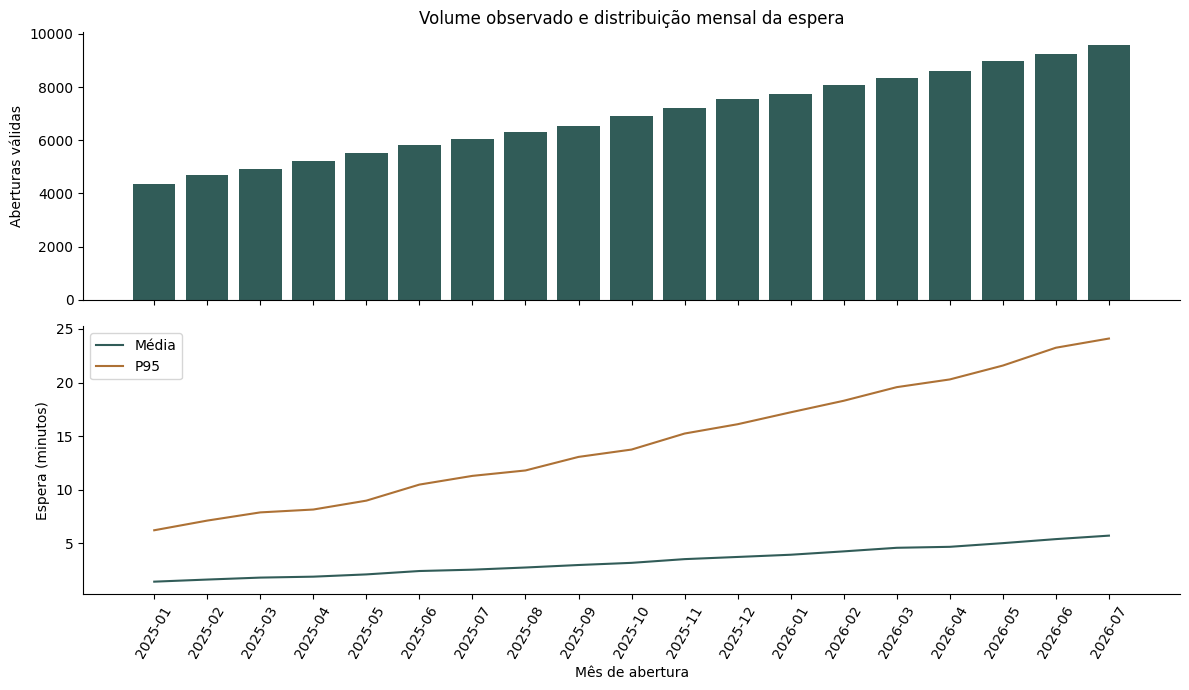

In [13]:
mensal = (volume.groupBy("mes_abertura").agg(F.count("id_chamado").alias("n_aberturas"),
    F.countDistinct("data_abertura").alias("dias_com_registro"),
    F.min("data_abertura").alias("primeiro_dia"), F.max("data_abertura").alias("ultimo_dia"),
    F.count("espera_s").alias("n_espera"), F.avg("espera_s").alias("espera_media_s"),
    F.expr("percentile(espera_s, 0.5)").alias("espera_p50_s"),
    F.expr("percentile(espera_s, 0.95)").alias("espera_p95_s"),
    F.count("atendimento_s").alias("n_atendimento"), F.avg("atendimento_s").alias("atendimento_media_s"))
    .orderBy("mes_abertura").toPandas())
mensal["mes"] = pd.to_datetime(mensal.mes_abertura).dt.strftime("%Y-%m")
mensal["variacao_volume_pct"] = mensal.n_aberturas.pct_change() * 100
mensal["cobertura_espera_pct"] = 100 * mensal.n_espera / mensal.n_aberturas
mensal["dias_intervalo"] = (pd.to_datetime(mensal.ultimo_dia) - pd.to_datetime(mensal.primeiro_dia)).dt.days + 1
mensal["aberturas_por_dia_intervalo"] = mensal.n_aberturas / mensal.dias_intervalo
for c in ["espera_media_s", "espera_p50_s", "espera_p95_s", "atendimento_media_s"]:
    mensal[c.replace("_s", "_min")] = mensal[c] / 60
assert mensal.n_aberturas.sum() == n_volume
display(mensal[["mes", "n_aberturas", "dias_com_registro", "aberturas_por_dia_intervalo", "variacao_volume_pct",
    "n_espera", "cobertura_espera_pct", "espera_media_min", "espera_p50_min", "espera_p95_min"]].round(2))
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].bar(mensal.mes, mensal.n_aberturas, color="#315c58")
axes[0].set(ylabel="Aberturas válidas", title="Volume observado e distribuição mensal da espera")
axes[1].plot(mensal.mes, mensal.espera_media_min, label="Média", color="#315c58")
axes[1].plot(mensal.mes, mensal.espera_p95_min, label="P95", color="#ad7135")
axes[1].set(xlabel="Mês de abertura", ylabel="Espera (minutos)"); axes[1].legend()
axes[1].tick_params(axis="x", rotation=60)
fig.tight_layout(); fig.savefig(SAIDA / "graficos/04_evolucao_mensal.png", dpi=170); plt.show()
assert len(mensal) == len(pd.period_range(pd.to_datetime(mensal.iloc[0].mes), pd.to_datetime(mensal.iloc[-1].mes), freq="M")), "Há meses ausentes; regularize o calendário mensal antes de usar lag como mês anterior."

## 10. Dia da semana × hora: onde se concentra a chegada?

**Pergunta:** quais janelas têm mais aberturas por dia de calendário?

Dividimos o total de cada combinação pelo número daquele dia da semana no intervalo do arquivo. Isso evita comparar diretamente totais de segundas-feiras e domingos quando existem quantidades diferentes desses dias no intervalo. A figura mostra **chegadas**, não ocupação de agentes ou necessidade de contratação. Faltam escalas e número de atendentes.

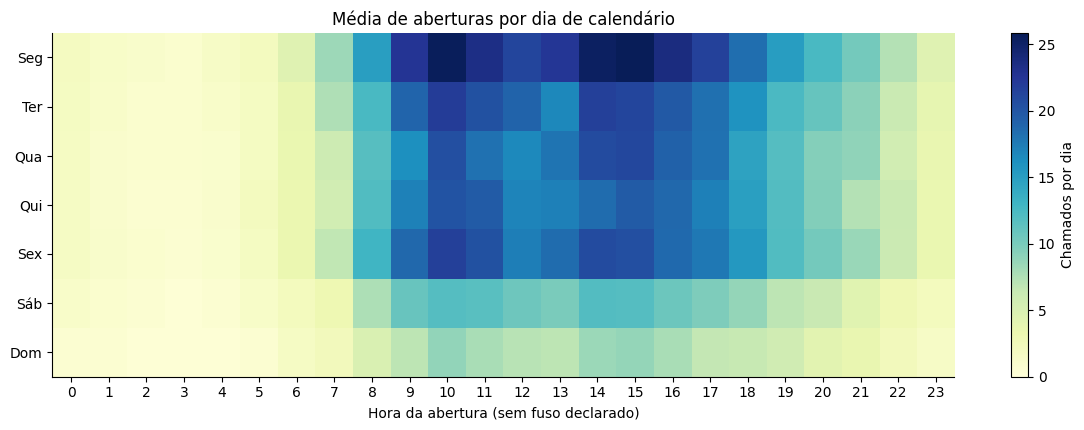

,dow,hora_abertura,n_aberturas,n_dias_calendario,aberturas_por_dia,n_espera
39,2,15,2121,82,25.87,2072
34,2,10,2099,82,25.60,2034
38,2,14,2074,82,25.29,2014
40,2,16,1939,82,23.65,1879
35,2,11,1914,82,23.34,1866
33,2,9,1849,82,22.55,1800
37,2,13,1835,82,22.38,1777
58,3,10,1801,82,21.96,1766
62,3,14,1774,82,21.63,1715
130,6,10,1795,83,21.63,1749


In [14]:
exposicao = (calendario.withColumn("dow", F.dayofweek("data"))
    .groupBy("dow").count().withColumnRenamed("count", "n_dias_calendario"))
horario = (volume.withColumn("dow", F.dayofweek("data_abertura"))
    .groupBy("dow", "hora_abertura").agg(F.count("id_chamado").alias("n_aberturas"),
        F.count("espera_s").alias("n_espera"), F.avg("espera_s").alias("espera_media_s")))
grade = exposicao.crossJoin(spark.range(24).select(F.col("id").cast("int").alias("hora_abertura")))
horario_pd = (grade.join(horario, ["dow", "hora_abertura"], "left")
    .fillna({"n_aberturas": 0, "n_espera": 0})
    .withColumn("aberturas_por_dia", F.col("n_aberturas") / F.col("n_dias_calendario"))
    .orderBy("dow", "hora_abertura").toPandas())
assert horario_pd.n_aberturas.sum() == n_volume
ordem_dias, nomes_dias = [2,3,4,5,6,7,1], ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
matriz = horario_pd.pivot(index="dow", columns="hora_abertura", values="aberturas_por_dia").reindex(ordem_dias)
fig, ax = plt.subplots(figsize=(12, 4.4))
im = ax.imshow(matriz, aspect="auto", cmap="YlGnBu", vmin=0)
ax.set_xticks(range(24), range(24)); ax.set_yticks(range(7), nomes_dias)
ax.set(xlabel="Hora da abertura (sem fuso declarado)", title="Média de aberturas por dia de calendário")
fig.colorbar(im, ax=ax, label="Chamados por dia"); fig.tight_layout()
fig.savefig(SAIDA / "graficos/05_calor_horario.png", dpi=170); plt.show()
display(horario_pd.nlargest(10, "aberturas_por_dia")[["dow", "hora_abertura", "n_aberturas", "n_dias_calendario", "aberturas_por_dia", "n_espera"]].round(2))

## 11. Limites de espera como cenários, sem inventar SLA

**Pergunta:** qual fração das esperas observáveis fica até 1, 5, 10, 15 ou 30 minutos?

Esses limites são **cenários**, não metas aprovadas. Os percentuais usam apenas esperas válidas. Também apresentamos limites matemáticos em relação a todas as aberturas elegíveis: no limite inferior, nenhum não classificável atende; no superior, todos atendem. São cenários de sensibilidade, não uma classificação real dessas linhas.

Um SLA só deve ser publicado após confirmar métrica, limite, população elegível, calendário e exceções. Horário útil exige calendário operacional e localidade. Este notebook mede duração nominal contínua.

,limite_min,ate_limite_n,n_esperas_validas,n_aberturas_elegiveis,n_nao_classificavel,pct_sobre_validas,limite_inferior_pct_elegiveis,limite_superior_pct_elegiveis
0,1,76201,128232,131640,3408,59.42,57.89,60.47
1,5,95255,128232,131640,3408,74.28,72.36,74.95
2,10,112589,128232,131640,3408,87.80,85.53,88.12
3,15,120529,128232,131640,3408,93.99,91.56,94.15
4,30,126934,128232,131640,3408,98.99,96.43,99.01


Sem SLA contratual informado: os resultados acima são apenas cenários.


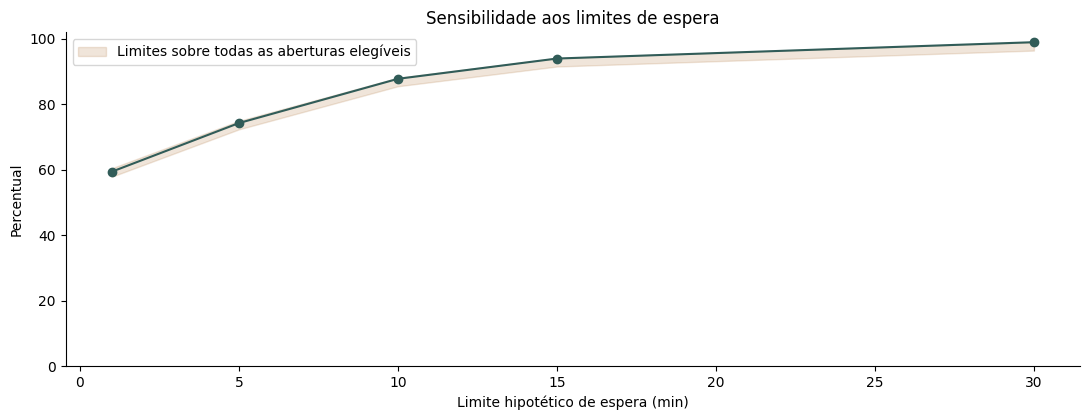

In [15]:
n_espera_valida = int(kpis.set_index("metrica").loc["espera", "n_validos"])
n_nao_classificavel = n_volume - n_espera_valida
expressoes = [F.sum(F.when(F.col("espera_s") <= limite * 60, 1).otherwise(0)).alias("m" + str(limite))
              for limite in LIMITES_CENARIO_MIN]
contagem_cenarios = volume.agg(*expressoes).first().asDict()
cenarios = pd.DataFrame([{"limite_min": limite, "ate_limite_n": int(contagem_cenarios["m" + str(limite)]),
    "n_esperas_validas": n_espera_valida, "n_aberturas_elegiveis": n_volume,
    "n_nao_classificavel": n_nao_classificavel,
    "pct_sobre_validas": 100 * contagem_cenarios["m" + str(limite)] / n_espera_valida,
    "limite_inferior_pct_elegiveis": 100 * contagem_cenarios["m" + str(limite)] / n_volume,
    "limite_superior_pct_elegiveis": 100 * (contagem_cenarios["m" + str(limite)] + n_nao_classificavel) / n_volume}
    for limite in LIMITES_CENARIO_MIN])
display(cenarios.round(2))
if SLA_CONTRATUAL_MIN is None:
    print("Sem SLA contratual informado: os resultados acima são apenas cenários.")
else:
    assert SLA_CONTRATUAL_MIN >= 0
    r_sla = volume.agg(F.sum(F.when(F.col("espera_s") <= SLA_CONTRATUAL_MIN * 60, 1).otherwise(0)).alias("n")).first()
    print(f"Limite configurado: {SLA_CONTRATUAL_MIN} min; {100*r_sla.n/n_espera_valida:.2f}% sobre esperas válidas.")
fig, ax = plt.subplots()
ax.plot(cenarios.limite_min, cenarios.pct_sobre_validas, "o-", color="#315c58")
ax.fill_between(cenarios.limite_min, cenarios.limite_inferior_pct_elegiveis,
    cenarios.limite_superior_pct_elegiveis, alpha=.18, color="#ad7135", label="Limites sobre todas as aberturas elegíveis")
ax.set(xlabel="Limite hipotético de espera (min)", ylabel="Percentual", ylim=(0, 102), title="Sensibilidade aos limites de espera")
ax.legend(); fig.tight_layout(); fig.savefig(SAIDA / "graficos/06_cenarios.png", dpi=170); plt.show()

## 12. Recorrência por cliente e limites de interpretação

Contamos chamados associados ao mesmo `ID_Cliente` dentro do recorte. Sem motivo, categoria ou vínculo entre chamados, recorrência não prova reabertura, falha de resolução ou insatisfação.

A tabela exportada só contém faixas agregadas. Os IDs individuais não aparecem no relatório compartilhável.

In [16]:
clientes = volume.filter("id_cliente IS NOT NULL").groupBy("id_cliente").agg(
    F.count("id_chamado").alias("n_chamados"), F.min("data_abertura").alias("primeiro_registro"),
    F.max("data_abertura").alias("ultimo_registro"))
recorrencia = (clientes.withColumn("faixa", F.when(F.col("n_chamados") == 1, "1")
    .when(F.col("n_chamados") <= 3, "2-3").when(F.col("n_chamados") <= 5, "4-5").otherwise("6+"))
    .groupBy("faixa").agg(F.count("id_cliente").alias("n_clientes"), F.sum("n_chamados").alias("n_chamados"))
    .orderBy("faixa").toPandas())
n_clientes = clientes.count()
display(recorrencia)
print(f"Clientes distintos com abertura válida: {n_clientes:,}.")

,faixa,n_clientes,n_chamados
0,1,5863,5863
1,2-3,12473,31377
2,4-5,8228,36554
3,6+,7611,57846


Clientes distintos com abertura válida: 34,175.


## 13. Validações e reconciliação

As verificações são sobre contratos de dados, não apenas sobre ausência de erro Python: unicidade, grão diário, agregações conciliadas, ausência de durações negativas publicadas e identidade temporal no mesmo conjunto.

Não fixamos os números esperados desta versão como regra para arquivos futuros. A reprodução deste arquivo é identificada por seu hash; contagens de qualidade podem mudar em outra extração e devem ser analisadas.

In [17]:
assert silver.select("id_chamado").distinct().count() == n_base
assert calendario.count() == (limites.fim - limites.inicio).days + 1
assert diario.select("data").distinct().count() == diario.count()
assert mensal.n_aberturas.sum() == n_volume
assert diario_pd.chamados_observados.sum() == n_volume
assert horario_pd.n_aberturas.sum() == n_volume
for c in ["espera_s", "atendimento_s", "total_s"]:
    assert analise.filter(F.col(c) < 0).count() == 0
assert erro_identidade == 0
print("VALIDACAO_OK: grãos, calendários, totais e identidade temporal conciliados.")

VALIDACAO_OK: grãos, calendários, totais e identidade temporal conciliados.


## 14. Conclusões calculadas com os dados

As conclusões abaixo são geradas a partir dos DataFrames deste notebook. As hipóteses operacionais ficam separadas dos achados. Não há estimativa de economia financeira, redução garantida ou dimensionamento de equipe sem as variáveis necessárias.

In [18]:
e = kpis.set_index("metrica").loc["espera"]
t = kpis.set_index("metrica").loc["total"]
crescimento = 100 * (mensal.iloc[-1].n_aberturas / mensal.iloc[0].n_aberturas - 1)
pico = horario_pd.loc[horario_pd.aberturas_por_dia.idxmax()]
rotulos_dia = dict(zip(ordem_dias, nomes_dias))
conclusoes = f"""### Achados observados
- O arquivo contém **{n_bruto:,} linhas**, **{n_exatas:,} duplicatas exatas** e **{conflitos:,} chaves conflitantes**.
- **{contagens['ausente_inicio_ts']:,}** chamados não têm início informado. **{contagens['abertura_futura']:,}** aberturas são posteriores a {DATA_REFERENCIA}. As flags podem se sobrepor.
- Espera: **{int(e.n_validos):,}** observações válidas; média **{e.media_min:.2f} min**, mediana **{e.p50_min:.2f} min** e P95 **{e.p95_min:.2f} min**.
- **{e.zeros_pct_validos:.2f}%** das esperas válidas são zero. Isso não identifica automaticamente um canal ou atendimento automatizado.
- Tempo total: média **{t.media_min:.2f} min** em **{int(t.n_validos):,}** observações, preservando os casos em que apenas o início está ausente.
- O volume mensal observado vai de **{mensal.iloc[0].n_aberturas:,}** em **{mensal.iloc[0].mes}** para **{mensal.iloc[-1].n_aberturas:,}** em **{mensal.iloc[-1].mes}**: variação de **{crescimento:.2f}%** entre esses dois meses. Não é crescimento anualizado nem previsão.
- A maior média de chegadas por dia de calendário aparece em **{rotulos_dia[int(pico.dow)]}, às {int(pico.hora_abertura)}h**: **{pico.aberturas_por_dia:.2f}** aberturas/dia nessa combinação.

### Hipóteses para investigar
- Verificar na origem se a ausência de início representa falha de captura ou uma etapa realmente não registrada.
- Investigar o significado de espera zero e a mistura de perfis antes de comparar produtividade.
- Confrontar as janelas de maior chegada com escalas e filas, sem inferir causa apenas pelo mapa de calor.

### Próximas ações
1. Corrigir as inconsistências na origem com rastreabilidade; não ajustar anos automaticamente.
2. Pactuar fuso, SLA, calendário operacional e população elegível.
3. Enriquecer com canal, categoria, equipe e escala, preservando o grão de chamado.
4. Só então estimar capacidade, impacto financeiro ou formular experimento de melhoria.
"""
display(Markdown(conclusoes))
(SAIDA / "resultados/conclusoes.md").write_text(conclusoes, encoding="utf-8")

### Achados observados
- O arquivo contém **131,838 linhas**, **0 duplicatas exatas** e **0 chaves conflitantes**.
- **3,414** chamados não têm início informado. **198** aberturas são posteriores a 2026-10-18. As flags podem se sobrepor.
- Espera: **128,232** observações válidas; média **3.60 min**, mediana **0.00 min** e P95 **16.37 min**.
- **58.44%** das esperas válidas são zero. Isso não identifica automaticamente um canal ou atendimento automatizado.
- Tempo total: média **14.65 min** em **131,639** observações, preservando os casos em que apenas o início está ausente.
- O volume mensal observado vai de **4,365** em **2025-01** para **9,577** em **2026-07**: variação de **119.40%** entre esses dois meses. Não é crescimento anualizado nem previsão.
- A maior média de chegadas por dia de calendário aparece em **Seg, às 15h**: **25.87** aberturas/dia nessa combinação.

### Hipóteses para investigar
- Verificar na origem se a ausência de início representa falha de captura ou uma etapa realmente não registrada.
- Investigar o significado de espera zero e a mistura de perfis antes de comparar produtividade.
- Confrontar as janelas de maior chegada com escalas e filas, sem inferir causa apenas pelo mapa de calor.

### Próximas ações
1. Corrigir as inconsistências na origem com rastreabilidade; não ajustar anos automaticamente.
2. Pactuar fuso, SLA, calendário operacional e população elegível.
3. Enriquecer com canal, categoria, equipe e escala, preservando o grão de chamado.
4. Só então estimar capacidade, impacto financeiro ou formular experimento de melhoria.


1586

## 15. Exportar agregados e preservar a trilha da análise

Os CSVs abaixo são tabelas de resultados, não uma nova fonte para calcular os tempos. A execução preserva o CSV original e não exporta IDs ou linhas individuais. As camadas detalhadas são persistidas localmente na pasta `camadas/`; o ZIP de compartilhamento inclui somente notebook, documentação e resultados agregados. Os dados por registro ficam disponíveis no diretório local da entrega.

A base de 12 MB cabe em uma análise local. PySpark é usado aqui para aplicar o fluxo das aulas; isso não implica que Spark seja necessário por tamanho. pandas recebe agregados, e não toda a Silver para executar as transformações.

In [19]:
saidas = {"qualidade": qualidade, "combinacoes_qualidade": combinacoes, "kpis": kpis,
    "mensal": mensal, "diario": diario_pd, "horario": horario_pd,
    "cenarios_espera": cenarios, "recorrencia": recorrencia, "faixas_espera": hist}
for nome, tabela in saidas.items():
    tabela.to_csv(SAIDA / f"resultados/{nome}.csv", index=False, encoding="utf-8-sig")
metadados.update({"n_bruto": n_bruto, "n_apos_deduplicacao": n_base,
    "n_aberturas_validas_escopo": n_volume, "n_problema": n_problema,
    "SLA_CONTRATUAL_MIN": SLA_CONTRATUAL_MIN, "limites_cenario_min": LIMITES_CENARIO_MIN,
    "contagens_qualidade_arquivo": contagens,
    "criterios": {"espera": "abertura <= inicio e datas até o corte", "atendimento": "abertura <= inicio <= fim",
                 "total": "abertura <= fim; inicio pode estar ausente"}})
(SAIDA / "resultados/metadados.json").write_text(json.dumps(metadados, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print(f"Exportados {len(saidas)} agregados, conclusões e metadados em {SAIDA / 'resultados'}.")

Exportados 9 agregados, conclusões e metadados em /home/perri/Documentos/ChatGPT/visagio/entregas/analise_chamados_jupyter/resultados.


## 16. Como continuar no contexto das aulas

**Feito neste notebook:** ingestão com schema, diagnóstico, parsing, flags de qualidade, deduplicação segura, indicadores com critérios explícitos, calendário contínuo, janela de sete dias, análises mensais/horárias e reconciliação.

**A fazer no ambiente do projeto:** migrar a persistência Parquet para Delta quando necessário, configurar Job, controle transacional de lotes e completude, permissões e alertas. Bronze/Silver/Gold e a tabela de ocorrências já são materializadas localmente por esta execução. Um Job verde não substitui as validações de grão e de resultado.

**SCD2:** este CSV é uma fotografia de eventos, sem atributos cadastrais versionados nem timestamp de alteração. Não crie um histórico de cliente fictício. Se uma dimensão versionada for adicionada, relacione o chamado com a versão válida na abertura usando `[inicio, fim)`.

**Feriados:** precisam de localidade e fonte de calendário. **Streaming/watermark:** não são necessários para explorar um arquivo estático e exigem outra arquitetura de ingestão.

**ML ou previsão:** primeiro confirme completude, fuso e significado dos tempos. Se houver objetivo preditivo, valide por corte temporal, usando apenas variáveis disponíveis no momento da previsão; evite usar a finalização para prever a espera na abertura.

### Perguntas para o responsável pelo processo
1. Que evento grava o início? Um início igual à abertura tem significado específico?
2. Qual o fuso dos horários e como foram tratadas mudanças históricas de relógio?
3. Os meses foram extraídos por completo? Houve mudança de sistema ou regra de geração?
4. Quais casos entram no SLA e ele mede minutos corridos ou úteis?
5. Qual coluna permite ligar canal, categoria, equipe e escala sem multiplicar chamados?

### Referências
- [Spark 3.5.6: try_to_timestamp](https://spark.apache.org/docs/3.5.6/api/python/reference/pyspark.sql/api/pyspark.sql.functions.try_to_timestamp.html)
- [Spark 3.5.6: tipos temporais](https://spark.apache.org/docs/3.5.6/sql-ref-datatypes.html)
- [Spark 3.5.6: funções SQL de data e tempo](https://spark.apache.org/docs/3.5.6/api/sql/index.html#timestampdiff)
- [Spark 3.5.6: Window.rangeBetween](https://spark.apache.org/docs/3.5.6/api/python/reference/pyspark.sql/api/pyspark.sql.Window.rangeBetween.html)

A estrutura e as interpretações conectam-se ao material Rocket Lab fornecido nesta conversa. Os números temporais vêm do CSV temporal atual. O arquivo chamados.csv é usado para auditar e enriquecer o vínculo, sem substituir os horários. Não reutilizamos resultados numéricos de relatórios anteriores.

## Gold física: fato, dimensões e agregados temporais

Publicamos uma fato detalhada e agregados de demanda. A fato contém somente aberturas válidas do escopo, com tempos inválidos como NULL e flags preservadas; a Silver guarda todas as linhas para auditoria. A tabela por hora usa `(data_abertura, hora_abertura)` como chave, cobrindo as 24 horas de cada data do intervalo observado.

A linha de calendário sem abertura registrada recebe volume 0 e tempos NULL, junto com `sem_registro=True`. Sem um controle de completude, esse zero significa **nenhum registro no arquivo**, não uma garantia de ausência de demanda real. Não particionamos por ID de chamado ou por hora: o tamanho atual permite poucas partes por tabela, evitando milhares de arquivos pequenos.

In [20]:
# Fato com dimensões em papéis temporais distintos; unidades base em segundos.
fato = (volume.withColumn("data_inicio", F.to_date("inicio_ts"))
    .withColumn("data_fim", F.to_date("fim_ts"))
    .withColumn("hora_inicio", F.hour("inicio_ts"))
    .withColumn("hora_fim", F.hour("fim_ts")))
fato = persistir(fato, "gold", "fato_chamados_temporais")
limites = fato.agg(F.min("data_abertura").alias("ini"), F.max("data_abertura").alias("fim")).first()
# Calendário abrange também os papéis início/fim observados e não futuros.
datas_papeis = (fato.select(F.col("data_abertura").alias("data"))
    .union(fato.select(F.col("data_inicio").alias("data")))
    .union(fato.select(F.col("data_fim").alias("data")))
    .filter(F.col("data").isNotNull() & (F.col("data") <= F.lit(DATA_REFERENCIA).cast("date"))))
lim_dim = datas_papeis.agg(F.min("data").alias("ini"), F.max("data").alias("fim")).first()
dim_data = (spark.range(1).select(F.explode(F.sequence(F.lit(lim_dim.ini), F.lit(lim_dim.fim))).alias("data"))
    .withColumn("ano", F.year("data")).withColumn("mes", F.month("data"))
    .withColumn("dia_semana", F.dayofweek("data"))
    .withColumn("fim_semana", F.col("dia_semana").isin(1, 7)))
dim_hora = spark.range(24).select(F.col("id").cast("int").alias("hora"))
dim_data = persistir(dim_data, "gold", "dim_data")
dim_hora = persistir(dim_hora, "gold", "dim_hora")

def agregar_tempos(df, chaves):
    medidas = [F.count("id_chamado").alias("n_aberturas")]
    for m in ["espera", "atendimento", "total"]:
        medidas += [F.count(m + "_s").alias("n_" + m), F.sum(m + "_s").alias("soma_" + m + "_s"),
            F.avg(m + "_s").alias("media_" + m + "_s"),
            F.expr(f"percentile({m}_s, 0.95)").alias("p95_" + m + "_s")]
    return df.groupBy(*chaves).agg(*medidas)

cal_abertura = dim_data.filter(F.col("data").between(F.lit(limites.ini), F.lit(limites.fim))).select(F.col("data").alias("data_abertura"))
horas = cal_abertura.crossJoin(dim_hora.select(F.col("hora").alias("hora_abertura")))
gold_hora = horas.join(agregar_tempos(fato, ["data_abertura", "hora_abertura"]), ["data_abertura", "hora_abertura"], "left")
gold_dia = cal_abertura.join(agregar_tempos(fato, ["data_abertura"]), "data_abertura", "left")
for nome, df in [("chamados_por_hora", gold_hora), ("chamados_por_dia", gold_dia)]:
    df = (df.withColumn("sem_registro", F.col("n_aberturas").isNull())
        .fillna(0, subset=["n_aberturas", "n_espera", "n_atendimento", "n_total"]))
    relido = persistir(df, "gold", nome)
    assert relido.agg(F.sum("n_aberturas")).first()[0] == n_volume
    chaves = ["data_abertura", "hora_abertura"] if nome.endswith("hora") else ["data_abertura"]
    assert relido.count() == relido.select(*chaves).distinct().count()
    relido.orderBy(*chaves).toPandas().to_csv(SAIDA / f"resultados/{nome}.csv", index=False)
    relido.createOrReplaceTempView("gold_" + nome)
    if nome.endswith("hora"):
        gold_hora = relido
    else:
        gold_dia = relido
fato.createOrReplaceTempView("gold_fato_chamados_temporais")
dim_data.createOrReplaceTempView("gold_dim_data")
dim_hora.createOrReplaceTempView("gold_dim_hora")
silver.createOrReplaceTempView("silver_chamados_temporais")
assert fato.count() == fato.select("id_chamado").distinct().count() == n_volume
# Integridade dos três papéis temporais para as métricas publicáveis.
for campo, validade in [("data_abertura", "abertura_valida"), ("data_inicio", "espera_valida"), ("data_fim", "total_valido")]:
    assert fato.filter(validade).select(F.col(campo).alias("data")).join(dim_data.select("data"), "data", "left_anti").count() == 0
print("VALIDACAO_CAMADAS_OK: grão, contagens e dimensões conferidos após leitura do disco.")

VALIDACAO_CAMADAS_OK: grão, contagens e dimensões conferidos após leitura do disco.


## Consultas SQL executadas sobre a Gold

Os aliases `gold_*` são views temporárias registradas a partir dos Parquets relidos. Em outra sessão, registre novamente as tabelas físicas antes das consultas. Os resultados SQL são exportados para CSV. A consulta de P95 por mês retorna ao fato; a média geral recomposta usa somas e denominadores, sem fazer média de médias horárias.

**Window functions:** `count` e `sum` com `Window.rangeBetween(-6, 0)` calculam a janela de sete dias após completar o calendário. Em SQL, `avg ... ROWS BETWEEN 6 PRECEDING AND CURRENT ROW` só equivale a sete dias porque a Gold diária tem uma linha por data. `lag` compara o mês atual ao mês anterior sem perder o grão mensal. Conferimos a continuidade dos meses antes de interpretar essa comparação.

In [21]:
consultas = {
"01_picos_data_hora": """SELECT data_abertura, hora_abertura, n_aberturas,
  n_espera, round(media_espera_s/60,2) AS espera_media_min,
  round(p95_espera_s/60,2) AS espera_p95_min,
  round(100.0*n_espera/nullif(n_aberturas,0),2) AS cobertura_espera_pct
FROM gold_chamados_por_hora ORDER BY n_aberturas DESC, data_abertura, hora_abertura LIMIT 20""",
"02_evolucao_diaria": """SELECT data_abertura, n_aberturas, sem_registro,
  CASE WHEN count(*) OVER (ORDER BY data_abertura ROWS BETWEEN 6 PRECEDING AND CURRENT ROW)=7
       THEN round(avg(n_aberturas) OVER (ORDER BY data_abertura ROWS BETWEEN 6 PRECEDING AND CURRENT ROW),2)
  END AS media_movel_7_dias
FROM gold_chamados_por_dia ORDER BY data_abertura""",
"03_perfil_semana_hora": """SELECT d.dia_semana, h.hora_abertura,
  count(*) AS dias_expostos, sum(h.n_aberturas) AS aberturas,
  round(avg(h.n_aberturas),2) AS aberturas_por_dia
FROM gold_chamados_por_hora h JOIN gold_dim_data d ON h.data_abertura=d.data
GROUP BY d.dia_semana,h.hora_abertura ORDER BY aberturas_por_dia DESC""",
"04_tempos_mensais": """SELECT trunc(data_abertura,'month') AS mes, count(*) AS aberturas,
  count(espera_s) AS n_espera, round(avg(espera_s)/60,2) AS espera_media_min,
  round(percentile(espera_s,0.95)/60,2) AS espera_p95_min,
  count(atendimento_s) AS n_atendimento, round(avg(atendimento_s)/60,2) AS atendimento_medio_min,
  count(total_s) AS n_total, round(avg(total_s)/60,2) AS total_medio_min
FROM gold_fato_chamados_temporais GROUP BY trunc(data_abertura,'month') ORDER BY mes""",
"05_qualidade_mensal": """SELECT trunc(data_abertura,'month') AS mes, count(*) AS chamados,
  sum(CASE WHEN tem_problema THEN 1 ELSE 0 END) AS problemas_temporais,
  sum(CASE WHEN cliente_divergente THEN 1 ELSE 0 END) AS divergencias_cliente,
  sum(CASE WHEN NOT contexto_encontrado THEN 1 ELSE 0 END) AS sem_contexto
FROM silver_chamados_temporais GROUP BY trunc(data_abertura,'month') ORDER BY mes""",
"06_media_recomposta": """SELECT sum(n_aberturas) AS aberturas, sum(n_espera) AS esperas_validas,
  round(sum(soma_espera_s)/nullif(sum(n_espera),0)/60,4) AS espera_media_min
FROM gold_chamados_por_hora""",
"07_cenario_espera_5min": """SELECT count(*) AS esperas_validas,
  sum(CASE WHEN espera_s <= 300 THEN 1 ELSE 0 END) AS ate_5min,
  round(100.0*sum(CASE WHEN espera_s <= 300 THEN 1 ELSE 0 END)/nullif(count(*),0),2) AS pct_validas
FROM gold_fato_chamados_temporais WHERE espera_s IS NOT NULL"""
}
consultas["08_variacao_mensal_window"] = """WITH mensal AS (
 SELECT trunc(data_abertura,'month') AS mes, count(*) AS n_aberturas
 FROM gold_fato_chamados_temporais GROUP BY trunc(data_abertura,'month')
), anterior AS (
 SELECT *, lag(n_aberturas) OVER (ORDER BY mes) AS mes_anterior FROM mensal
)
SELECT *, round(100.0*(n_aberturas-mes_anterior)/nullif(mes_anterior,0),2) AS variacao_pct
FROM anterior ORDER BY mes"""
for nome, sql in consultas.items():
    resultado = spark.sql(sql).toPandas()
    display(Markdown(f"**{nome}**")); display(resultado.head(10))
    resultado.to_csv(SAIDA / f"resultados/sql_{nome}.csv", index=False)
(SAIDA / "consultas_analiticas.sql").write_text("\n\n".join(f"-- {nome}\n{sql};" for nome, sql in consultas.items()), encoding="utf-8")
metadados.update({"lote_processado": LOTE, "sha256_contexto": lote_contexto,
                  "raiz_camadas": str(RAIZ_LOTE), "formato_camadas": "parquet",
                  "auditoria_vinculo": resumo_vinculo, "validacao_camadas": "OK"})
(SAIDA / "resultados/metadados.json").write_text(json.dumps(metadados, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("Consultas executadas; Gold persistida em", RAIZ_LOTE / "gold")

**01_picos_data_hora**

,data_abertura,hora_abertura,n_aberturas,n_espera,espera_media_min,espera_p95_min,cobertura_espera_pct
0,2025-08-18,16,52,51,3.80,13.23,98.08
1,2026-03-23,13,51,50,4.93,15.04,98.04
2,2026-04-27,10,51,49,5.13,19.73,96.08
3,2026-05-22,11,50,49,6.10,20.79,98.00
4,2025-10-20,16,49,47,3.23,12.53,95.92
5,2026-04-06,11,49,49,4.11,17.34,100.00
6,2026-04-20,15,49,49,4.83,18.81,100.00
7,2026-07-21,10,49,47,4.47,16.80,95.92
8,2026-03-30,11,48,48,3.64,16.24,100.00
9,2026-06-08,10,47,47,6.01,27.79,100.00


**02_evolucao_diaria**

,data_abertura,n_aberturas,sem_registro,media_movel_7_dias
0,2025-01-01,116,False,NaN
1,2025-01-02,118,False,NaN
2,2025-01-03,166,False,NaN
3,2025-01-04,95,False,NaN
4,2025-01-05,71,False,NaN
5,2025-01-06,168,False,NaN
6,2025-01-07,179,False,130.43
7,2025-01-08,142,False,134.14
8,2025-01-09,160,False,140.14
9,2025-01-10,152,False,138.14


**03_perfil_semana_hora**

...

**07_cenario_espera_5min**

,esperas_validas,ate_5min,pct_validas
0,128232,95255,74.28


**08_variacao_mensal_window**

,mes,n_aberturas,mes_anterior,variacao_pct
0,2025-01-01,4365,NaN,None
1,2025-02-01,4681,4365.0,7.24
2,2025-03-01,4915,4681.0,5.00
3,2025-04-01,5210,4915.0,6.00
4,2025-05-01,5501,5210.0,5.59
5,2025-06-01,5817,5501.0,5.74
6,2025-07-01,6063,5817.0,4.23
7,2025-08-01,6314,6063.0,4.14
8,2025-09-01,6548,6314.0,3.71
9,2025-10-01,6928,6548.0,5.80


Consultas executadas; Gold persistida em /home/perri/Documentos/ChatGPT/visagio/entregas/analise_chamados_jupyter/camadas/processado/d971b56d13d145cf_feb33076a4396b61/gold


In [22]:
# Libera caches. Mantém disponível uma sessão fornecida pelo ambiente.
analise.unpersist()
volume.unpersist()
bronze.unpersist()
if spark_existente is None:
    spark.stop()
print("Análise concluída.")

Análise concluída.


## Apresentação final: cinco páginas

1. Modelagem temporal, grão e escolha de batch com ELT.
2. Bronze bruta, análise introdutória e rastreabilidade.
3. Prata com regex, parsing e regras de qualidade.
4. Window functions para média móvel e comparação mensal.
5. Gold, tabelas publicadas, consultas e resultados.

[Slides em PDF](slides/apresentacao_chamados_5_paginas.pdf) · [Apresentação editável](slides/apresentacao_chamados_5_paginas.pptx)

Execução das camadas e consultas validada localmente. Para executar no Databricks, ajuste `path`, `path_chamados` e `path_saida` na célula de parâmetros para caminhos `/Volumes/...` acessíveis pelo Python e pelo Spark. Consulte o README para a configuração.